# Project 3 — Grifols: secured 2030s or unsecured 2028s?
Runs `src/model.py` (reproduced with formulas in `model/grifols_credit_model.xlsx`, checked by `src/check_workbook.py`)
and draws the charts used in the memo.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent)]

import numpy as np
import pandas as pd

from common.plotting import PALETTE, setup, source
from src import model as M

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
R = M.run()
H = pd.read_csv(DATA / "credit_history.csv", index_col=0)
R["rv"]

,7.125% secured 2030,3.875% unsecured 2028
price,104.1,97.47
YTW,0.032827,0.052806
worst,call 2027-05-01 at 102,maturity 2028-10-15
YTM,0.059171,0.052806
years to worst,0.558522,2.017796
Bund (matched),0.0292,0.030707
spread,0.003627,0.022099
leverage through tranche (x),2.6511,4.185722
spread per turn (bp),13.68277,52.79554
recovery,1.0,1.0


In [2]:
print("gap (secured − unsecured expected return):", round(R["gap"] * 1e4, 1), "bp ->", R["rec"])
print("proportionate leverage:", {k: round(v, 2) for k, v in R["prop"].items()})
print("break-even multiples: secured", round(R["be_sec"], 2), "unsecured", round(R["be_uns"], 2),
      "| gap zero at", round(R["m_flip"], 2), "x; neutral band at", round(R["m_neutral"], 2), "x")
print("secured price for gap zero", round(R["px_flip"], 2), "| for −50bp", round(R["px_neutral"], 2))
pd.DataFrame({"base": R["refi_base"], "downside": R["refi_down"]})

gap (secured − unsecured expected return): -199.8 bp -> Overweight the 3.875% unsecured 2028s, Underweight the 7.125% secured 2030s
proportionate leverage: {'EBITDA': np.float64(1757.73), 'Net debt': np.float64(8214.34), 'Leverage': np.float64(4.67)}
break-even multiples: secured 3.61 unsecured 5.26 | gap zero at 4.55 x; neutral band at 4.72 x
secured price for gap zero 102.83 | for −50bp 103.26


,base,downside
Net debt Oct 2028,6176.342159,6733.588409
Credit-agreement EBITDA (LTM Oct 2028),2160.054,1913.17275
Net leverage Oct 2028 (x),2.859346,3.519592
Unsecured notes due Oct 2028,2018.774436,2018.774436
"Cash + undrawn RCF, 30 Jun 2026",1974.438596,1974.438596
"FCF after dividends, Jul 2026 – Oct 2028",1621.657841,1064.411591
Liquidity available before maturity,3596.096438,3038.850188
Liquidity / notes due (x),1.781327,1.505295
Leverage at or below 3.5x target,True,False


In [3]:
pd.concat({"Base": R["base"], "Downside": R["down"]}).round(2)

2026     2027     2028
Base     Revenue                      7524.00  7900.20  8295.21
         EBITDA margin                   0.25     0.26     0.26
         Adjusted EBITDA              1881.00  2014.55  2156.75
         Cash interest                 492.65   492.65   492.65
         Capex, IT & R&D               530.00   530.00   530.00
         Taxes                         170.00   170.00   170.00
         Working capital                60.00    60.00    60.00
         Other                          70.00    70.00    70.00
         FCF pre-dividends             558.35   691.90   834.10
         Dividends                     128.00   128.00   128.00
         Net debt (Credit Agreement)  7328.65  6764.76  6058.66
         Credit-agreement EBITDA      1908.00  2041.55  2183.75
         Net leverage (x)                3.84     3.31     2.77
         EBITDA / cash interest (x)      3.82     4.09     4.38
Downside Revenue                      7524.00  7900.20  8295.21
         EBITDA margin                   0.24     0.22     0.23
         Adjusted EBITDA              1768.14  1777.55  1907.90
         Cash interest                 492.65   492.65   492.65
         Capex, IT & R&D               530.00   530.00   530.00
         Taxes                         170.00   170.00   170.00
         Working capital                60.00    60.00    60.00
         Other                          70.00    70.00    70.00
         FCF pre-dividends             445.49   454.89   585.24
         Dividends                     128.00   128.00   128.00
         Net debt (Credit Agreement)  7441.51  7114.62  6657.38
         Credit-agreement EBITDA      1795.14  1804.55  1934.90
         Net leverage (x)                4.15     3.94     3.44
         EBITDA / cash interest (x)      3.59     3.61     3.87

## Charts

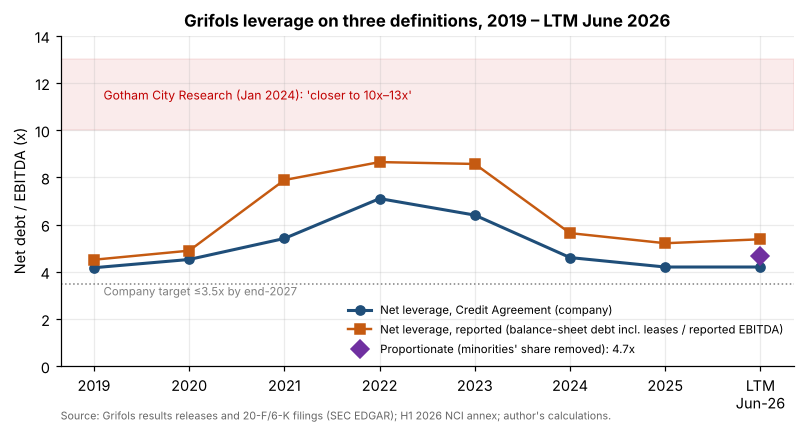

In [4]:
cols = list(H.columns)
fig, ax = plt.subplots(figsize=(8.6, 3.9))
x = np.arange(len(cols))
ax.plot(x, H.loc["Net leverage, Credit Agreement (x)"], marker="o", color=PALETTE[0], lw=2, label="Net leverage, Credit Agreement (company)")
ax.plot(x, H.loc["Net leverage, reported (x)"], marker="s", color=PALETTE[1], lw=1.6,
        label="Net leverage, reported (balance-sheet debt incl. leases / reported EBITDA)")
ax.plot([x[-1]], [R["prop"]["Leverage"]], marker="D", color=PALETTE[4], ms=8, ls="none",
        label=f"Proportionate (minorities' share removed): {R['prop']['Leverage']:.1f}x")
ax.axhspan(10, 13, color="#C00000", alpha=0.08)
ax.text(0.1, 11.3, "Gotham City Research (Jan 2024): 'closer to 10x–13x'", fontsize=8, color="#C00000")
ax.axhline(3.5, color="grey", ls=":", lw=1); ax.text(0.1, 3.0, "Company target ≤3.5x by end-2027", fontsize=7.5, color="grey")
ax.set_xticks(x, [c.replace("LTM Jun-26", "LTM\nJun-26") for c in cols]); ax.set_ylabel("Net debt / EBITDA (x)"); ax.set_ylim(0, 14)
ax.legend(fontsize=7.5, loc="lower right"); ax.set_title("Grifols leverage on three definitions, 2019 – LTM June 2026")
source(ax, "Source: Grifols results releases and 20-F/6-K filings (SEC EDGAR); H1 2026 NCI annex; author's calculations.")
fig.savefig(FIG / "fig_leverage.png"); plt.show()

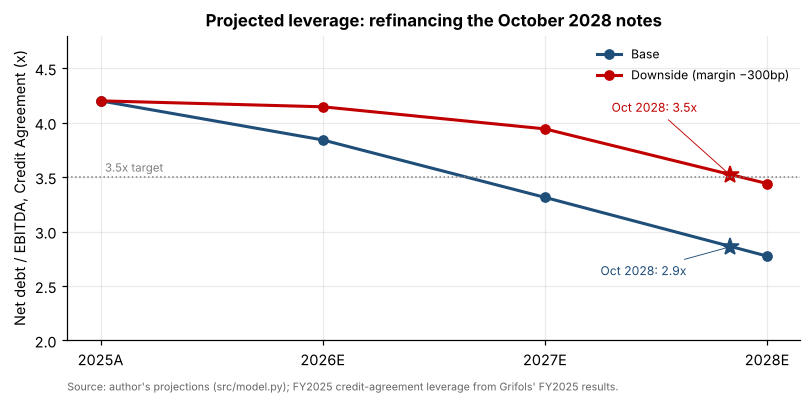

In [5]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
yrs = [2025, 2026, 2027, 2028]
for nm, df, c in [("Base", R["base"], PALETTE[0]), ("Downside (margin −300bp)", R["down"], PALETTE[8])]:
    lev = [H.loc["Net leverage, Credit Agreement (x)", "2025"]] + list(df.loc["Net leverage (x)", [2026, 2027, 2028]])
    ax.plot(yrs, lev, marker="o", color=c, lw=2, label=nm)
    k = R["refi_base"] if nm == "Base" else R["refi_down"]
    ax.plot([2027 + 10 / 12], [k["Net leverage Oct 2028 (x)"]], marker="*", ms=12, color=c)
    ax.annotate(f"Oct 2028: {k['Net leverage Oct 2028 (x)']:.1f}x", (2027 + 10 / 12, k["Net leverage Oct 2028 (x)"]),
                xytext=(2027.25, 2.6) if nm == "Base" else (2027.3, 4.1), textcoords="data", fontsize=8, color=c,
                arrowprops=dict(arrowstyle="-", color=c, lw=0.6))
ax.axhline(3.5, color="grey", ls=":", lw=1); ax.text(2025.02, 3.55, "3.5x target", fontsize=7.5, color="grey")
ax.set_xticks(yrs, ["2025A", "2026E", "2027E", "2028E"]); ax.set_ylabel("Net debt / EBITDA, Credit Agreement (x)")
ax.set_ylim(2, 4.8); ax.legend(fontsize=8, loc="upper right")
ax.set_title("Projected leverage: refinancing the October 2028 notes")
source(ax, "Source: author's projections (src/model.py); FY2025 credit-agreement leverage from Grifols' FY2025 results.")
fig.savefig(FIG / "fig_projection.png"); plt.show()

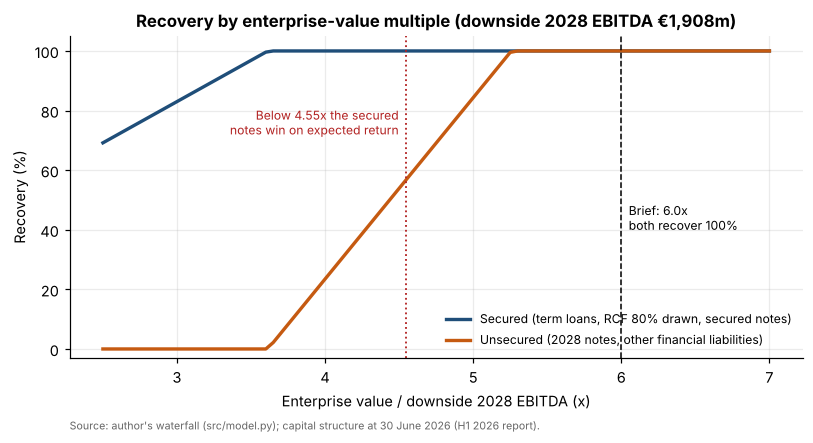

In [6]:
e = R["down"].loc["Adjusted EBITDA", 2028]
ms = np.linspace(2.5, 7.0, 91)
sec = [M.waterfall(e, m)["Secured recovery"] for m in ms]
uns = [M.waterfall(e, m)["Unsecured recovery"] for m in ms]
fig, ax = plt.subplots(figsize=(8.6, 3.8))
ax.plot(ms, np.array(sec) * 100, color=PALETTE[0], lw=2.2, label="Secured (term loans, RCF 80% drawn, secured notes)")
ax.plot(ms, np.array(uns) * 100, color=PALETTE[1], lw=2.2, label="Unsecured (2028 notes, other financial liabilities)")
ax.axvline(M.MULTIPLE, color="black", ls="--", lw=1); ax.text(M.MULTIPLE + 0.05, 40, "Brief: 6.0x\nboth recover 100%", fontsize=8)
ax.axvline(R["m_flip"], color="#B22222", ls=":", lw=1.2)
ax.text(R["m_flip"] - 0.05, 72, f"Below {R['m_flip']:.2f}x the secured\nnotes win on expected return", fontsize=8, color="#B22222", ha="right")
ax.set_xlabel("Enterprise value / downside 2028 EBITDA (x)"); ax.set_ylabel("Recovery (%)"); ax.set_ylim(-3, 105)
ax.legend(fontsize=8, loc="lower right"); ax.set_title(f"Recovery by enterprise-value multiple (downside 2028 EBITDA €{e:,.0f}m)")
source(ax, "Source: author's waterfall (src/model.py); capital structure at 30 June 2026 (H1 2026 report).")
fig.savefig(FIG / "fig_recovery.png"); plt.show()

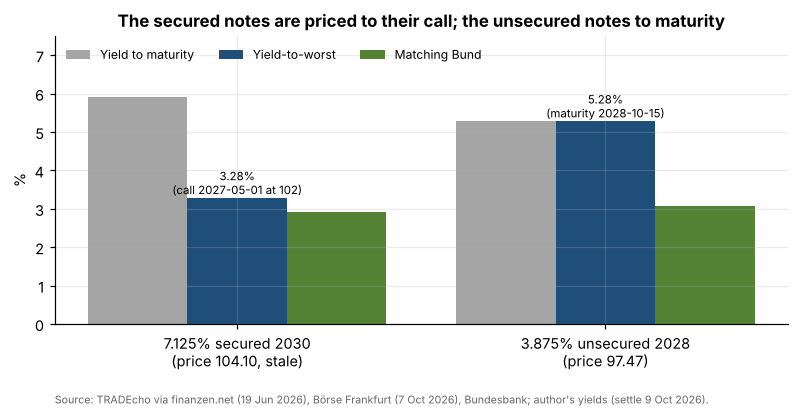

In [7]:
rv = R["rv"]
fig, ax = plt.subplots(figsize=(8.6, 3.4))
lab = ["7.125% secured 2030\n(price 104.10, stale)", "3.875% unsecured 2028\n(price 97.47)"]
k = ["7.125% secured 2030", "3.875% unsecured 2028"]
x = np.arange(2)
ax.bar(x - 0.27, [rv.loc["YTM", c] * 100 for c in k], 0.27, color=PALETTE[7], label="Yield to maturity")
ax.bar(x, [rv.loc["YTW", c] * 100 for c in k], 0.27, color=PALETTE[0], label="Yield-to-worst")
ax.bar(x + 0.27, [rv.loc["Bund (matched)", c] * 100 for c in k], 0.27, color=PALETTE[2], label="Matching Bund")
for i, c in enumerate(k):
    ax.text(i, rv.loc["YTW", c] * 100 + 0.1, f"{rv.loc['YTW', c]:.2%}\n({rv.loc['worst', c]})", ha="center", fontsize=7.5)
ax.set_xticks(x, lab); ax.set_ylabel("%"); ax.set_ylim(0, 7.5); ax.legend(fontsize=8, loc="upper left", ncol=3)
ax.set_title("The secured notes are priced to their call; the unsecured notes to maturity")
ax.annotate("Source: TRADEcho via finanzen.net (19 Jun 2026), Börse Frankfurt (7 Oct 2026), Bundesbank; author's yields (settle 9 Oct 2026).",
            xy=(0, -0.24), xycoords="axes fraction", fontsize=7, color="#666666", ha="left", va="top")
fig.savefig(FIG / "fig_yields.png"); plt.show()

## Save

In [8]:
R["base"].to_csv(DATA / "out_projection_base.csv"); R["down"].to_csv(DATA / "out_projection_downside.csv")
R["rv"].to_csv(DATA / "out_relative_value.csv"); R["grid"].to_csv(DATA / "out_recovery_grid.csv")
json.dump({k: R[k] for k in ["w_base", "w_down", "gap", "rec", "hy_oas", "sp", "plasma_eq", "bund", "prop", "refi_base", "refi_down",
                             "be_sec", "be_uns", "px_neutral", "px_flip", "m_flip", "m_neutral"]} |
          {"yields": {k: {kk: vv for kk, vv in v.items() if kk != "candidates"} | {"candidates": v["candidates"]} for k, v in R["yields"].items()}},
          open(DATA / "out_results.json", "w"), indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))